<center><h1>Last_First_HW5</h1></center>
<br>
<br>

Name: Jialegong
<br>
Github Username: Jialegong
<br>
USC ID: 1387502580

## 1. Decision Trees as Interpretable Models

Import packages

In [78]:
import io
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pandas.api.types import is_string_dtype
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import RidgeCV
from sklearn.linear_model import LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV


### (a) Obtain Data

Get the Accute Inamations Data Set

In [20]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/acute/diagnosis.data"
try:
    response = requests.get(url)
    response.raise_for_status()
    df = pd.read_csv(
        io.BytesIO(response.content),
        sep="\t",
        header=None,
        decimal=",",          
        encoding="utf-16",
    )
except Exception:
    import openml
    dataset = openml.datasets.get_dataset(1556)
    X_tmp, y_tmp, _, _ = dataset.get_data(target=dataset.default_target_attribute)
    df = X_tmp.copy()
    df["target"] = y_tmp

feature_names = [
    "temperature", "nausea", "lumbar_pain",
    "urine_pushing", "micturition_pains", "burning_itch_swelling",
]
target_names = ["bladder_inflammation", "nephritis"]
df.columns = feature_names + target_names

for col in df.columns:
    if is_string_dtype(df[col]):
        df[col] = df[col].replace({"yes": 1, "no": 0})

df = df.apply(pd.to_numeric, errors="coerce")

print("NaN counts per column (should all be 0):\n", df.isna().sum())

X = df[feature_names].astype(float).copy()
y = df["bladder_inflammation"].astype(int).copy()

print("\nSamples:", X.shape[0], "| Features:", X.shape[1])
print("\nX dtypes:\n", X.dtypes)
print("\nClass distribution:\n", y.value_counts())
print("\nFirst 3 rows of X:\n", X.head(3))

NaN counts per column (should all be 0):
 temperature              0
nausea                   0
lumbar_pain              0
urine_pushing            0
micturition_pains        0
burning_itch_swelling    0
bladder_inflammation     0
nephritis                0
dtype: int64

Samples: 120 | Features: 6

X dtypes:
 temperature              float64
nausea                   float64
lumbar_pain              float64
urine_pushing            float64
micturition_pains        float64
burning_itch_swelling    float64
dtype: object

Class distribution:
 bladder_inflammation
0    61
1    59
Name: count, dtype: int64

First 3 rows of X:
    temperature  nausea  lumbar_pain  urine_pushing  micturition_pains  \
0         35.5     0.0          1.0            0.0                0.0   
1         35.9     0.0          0.0            1.0                1.0   
2         35.9     0.0          1.0            0.0                0.0   

   burning_itch_swelling  
0                    0.0  
1                    1.0

/var/folders/k1/kqgwdh7d5y1fn02tg8x4d9k80000gn/T/ipykernel_33618/3935214676.py:28: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[col] = df[col].replace({"yes": 1, "no": 0})


### (b) Build a decision tree

Unpruned depth: 3, leaves: 4


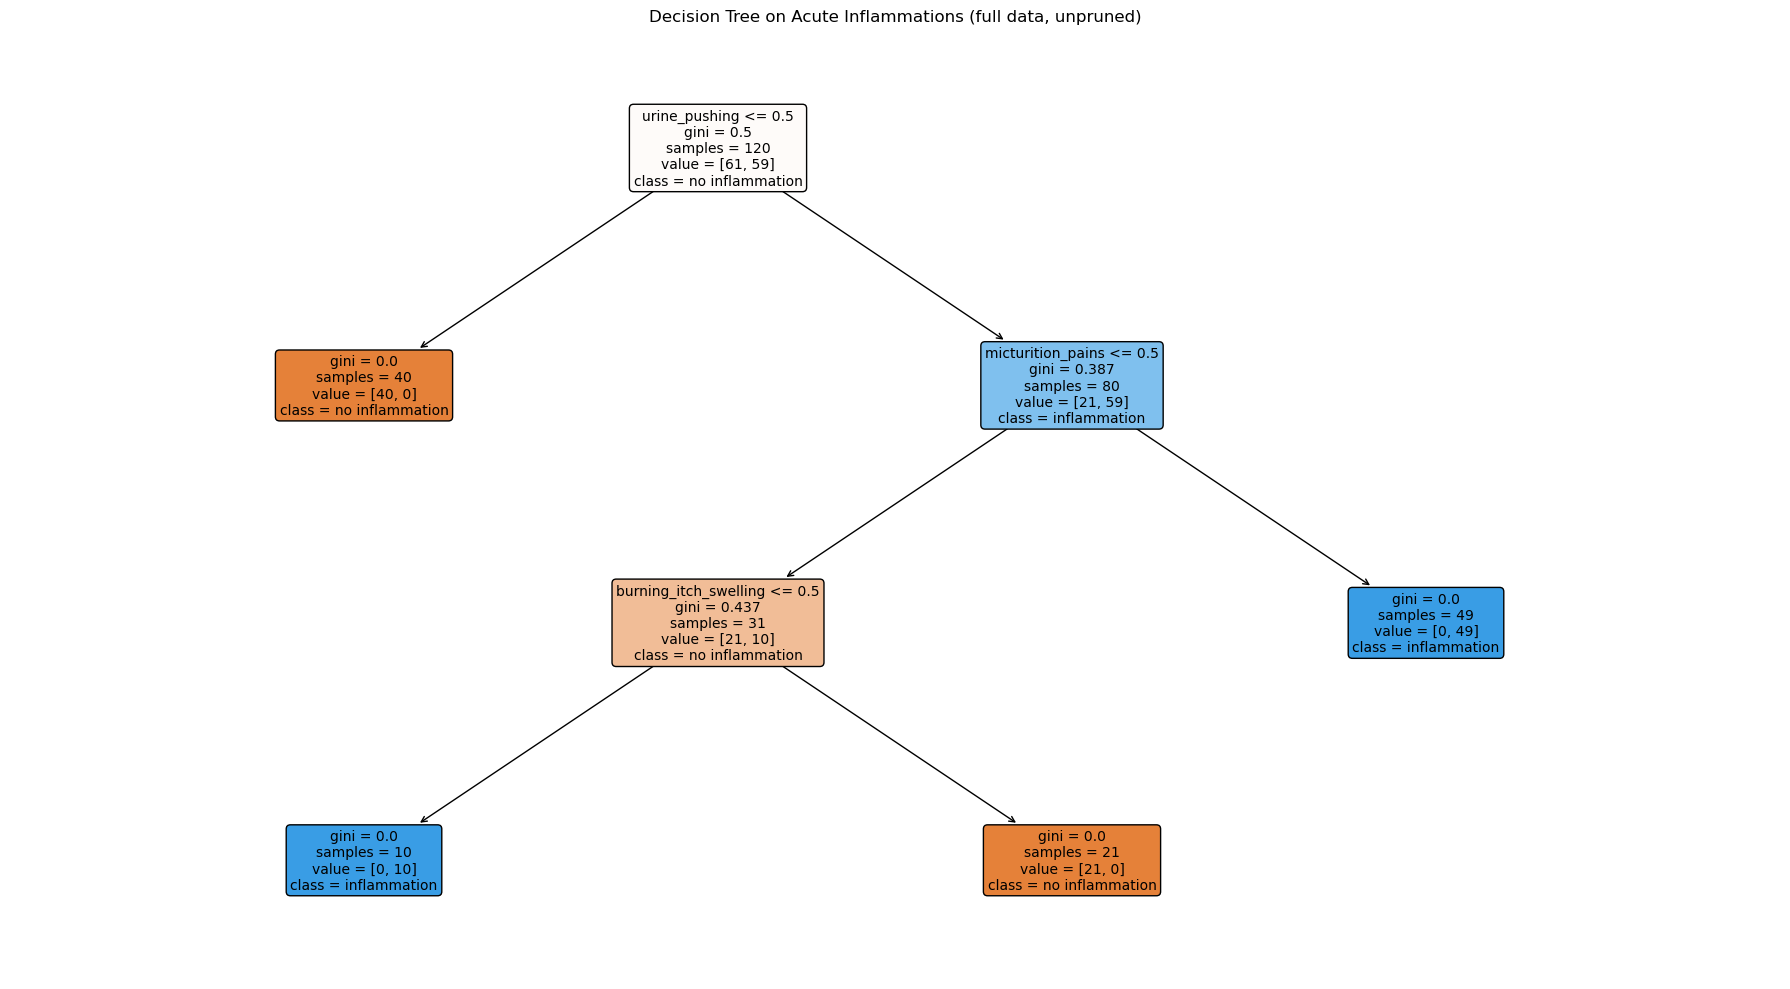

In [24]:
clf_full = DecisionTreeClassifier(random_state=42)
clf_full.fit(X, y)

print(f"Unpruned depth: {clf_full.get_depth()}, leaves: {clf_full.get_n_leaves()}")

plt.figure(figsize=(18, 10))
plot_tree(
    clf_full,
    feature_names=feature_names,
    class_names=["no inflammation", "inflammation"],
    filled=True,
    rounded=True,
    impurity=True,
    proportion=False,
    fontsize=10,
)
plt.title("Decision Tree on Acute Inflammations (full data, unpruned)")
plt.tight_layout()
plt.show()

### (c) Convert the decision rules

In [34]:
def extract_if_then_rules(tree, feature_names, class_names):
    tree_ = tree.tree_
    rules = []

    def recurse(node, conditions):
        if tree_.feature[node] != -2:  
            name = feature_names[tree_.feature[node]]
            threshold = tree_.threshold[node]
            recurse(tree_.children_left[node],
                    conditions + [f"{name} <= {threshold:.3f}"])
            recurse(tree_.children_right[node],
                    conditions + [f"{name} > {threshold:.3f}"])
        else:  
            value = tree_.value[node][0]
            pred_class = class_names[np.argmax(value)]
            n_samples = tree_.n_node_samples[node]
            if conditions:
                rule = "IF " + " AND ".join(conditions) + \
                       f" THEN {pred_class} (n={n_samples})"
            else:
                rule = f"ELSE {pred_class} (n={n_samples})"
            rules.append(rule)

    recurse(0, [])
    return rules

rules_full = extract_if_then_rules(clf_full, feature_names, ["no", "yes"])
print(f"Extracted {len(rules_full)} rules:\n")
for r in rules_full:
    print(r)

Extracted 4 rules:

IF urine_pushing <= 0.500 THEN no (n=40)
IF urine_pushing > 0.500 AND micturition_pains <= 0.500 AND burning_itch_swelling <= 0.500 THEN yes (n=10)
IF urine_pushing > 0.500 AND micturition_pains <= 0.500 AND burning_itch_swelling > 0.500 THEN no (n=21)
IF urine_pushing > 0.500 AND micturition_pains > 0.500 THEN yes (n=49)


### (d) find a minimal decision tree and a set of decision rules with high interpretability

Best ccp_alpha = 0.000000, CV accuracy = 1.0000
Pruned depth: 3, leaves: 4


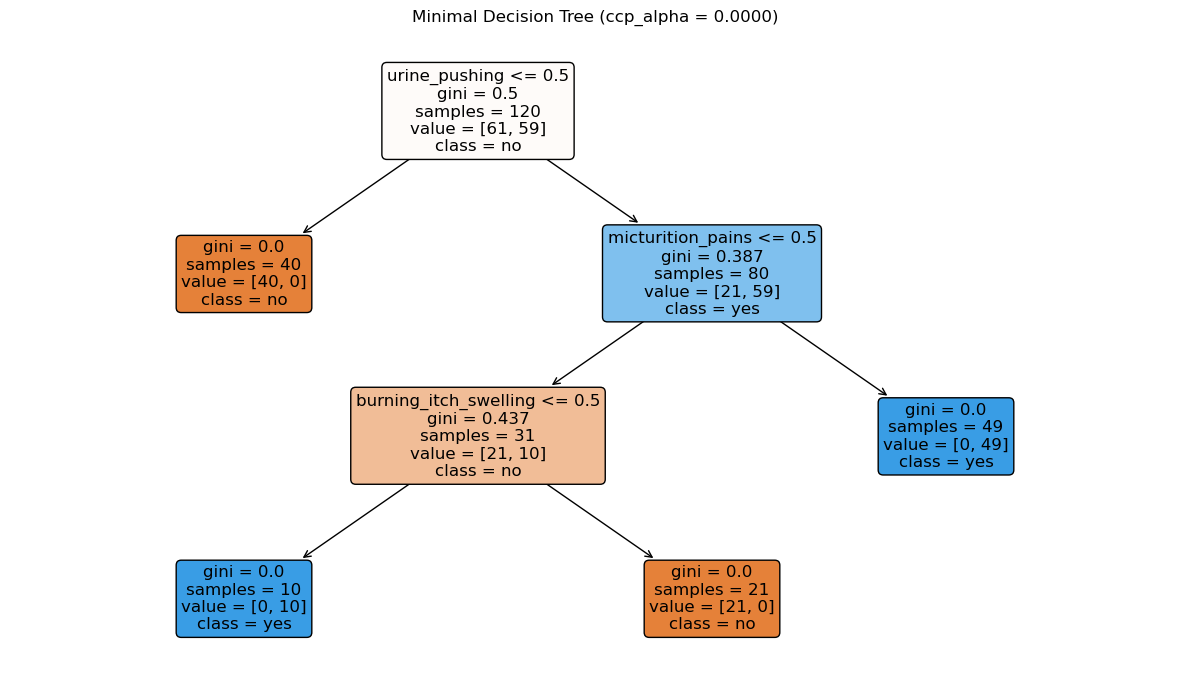


Pruned tree has 4 rules:

IF urine_pushing <= 0.500 THEN no (n=40)
IF urine_pushing > 0.500 AND micturition_pains <= 0.500 AND burning_itch_swelling <= 0.500 THEN yes (n=10)
IF urine_pushing > 0.500 AND micturition_pains <= 0.500 AND burning_itch_swelling > 0.500 THEN no (n=21)
IF urine_pushing > 0.500 AND micturition_pains > 0.500 THEN yes (n=49)


In [37]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

path = clf_full.cost_complexity_pruning_path(X, y)
ccp_alphas = path.ccp_alphas
ccp_alphas = ccp_alphas[:-1]  

cv_scores = []
for alpha in ccp_alphas:
    clf = DecisionTreeClassifier(random_state=42, ccp_alpha=alpha)
    scores = cross_val_score(clf, X, y, cv=cv, scoring="accuracy")
    cv_scores.append(scores.mean())

best_idx = int(np.argmax(cv_scores))
best_alpha = ccp_alphas[best_idx]
best_score = cv_scores[best_idx]
print(f"Best ccp_alpha = {best_alpha:.6f}, CV accuracy = {best_score:.4f}")

clf_pruned = DecisionTreeClassifier(random_state=42, ccp_alpha=best_alpha)
clf_pruned.fit(X, y)

print(f"Pruned depth: {clf_pruned.get_depth()}, leaves: {clf_pruned.get_n_leaves()}")

plt.figure(figsize=(12, 7))
plot_tree(
    clf_pruned,
    feature_names=feature_names,
    class_names=["no", "yes"],
    filled=True,
    rounded=True,
    fontsize=12,
)
plt.title(f"Minimal Decision Tree (ccp_alpha = {best_alpha:.4f})")
plt.tight_layout()
plt.show()

rules_pruned = extract_if_then_rules(clf_pruned, feature_names, ["no", "yes"])
print(f"\nPruned tree has {len(rules_pruned)} rules:\n")
for r in rules_pruned:
    print(r)

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [39]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/communities/communities.data"
response = requests.get(url)
response.raise_for_status()

df = pd.read_csv(io.BytesIO(response.content), header=None, na_values="?")

df = df.drop(columns=[0, 1, 2, 3, 4])

X_all = df.iloc[:, :-1]
y_all = df.iloc[:, -1]

X_train_raw = X_all.iloc[:1495].copy()
y_train = y_all.iloc[:1495].copy()
X_test_raw = X_all.iloc[1495:].copy()
y_test = y_all.iloc[1495:].copy()

print(f"Original dataset shape: {df.shape}")
print(f"Train set: {X_train_raw.shape[0]} samples, {X_train_raw.shape[1]} features")
print(f"Test set:  {X_test_raw.shape[0]} samples, {X_test_raw.shape[1]} features")

Original dataset shape: (1994, 123)
Train set: 1495 samples, 122 features
Test set:  499 samples, 122 features


### (b) Missing values

In [45]:
imputer = SimpleImputer(strategy="median")

imputer.fit(X_train_raw)

X_train = pd.DataFrame(imputer.transform(X_train_raw), columns=X_train_raw.columns)
X_test = pd.DataFrame(imputer.transform(X_test_raw), columns=X_test_raw.columns)

print(f"Remaining missing values in train: {X_train.isna().sum().sum()}")
print(f"Remaining missing values in test:  {X_test.isna().sum().sum()}")

print("\nFirst 3 rows of X_train after imputation:")
print(X_train.head(3))

Remaining missing values in train: 0
Remaining missing values in test:  0

First 3 rows of X_train after imputation:
    5     6     7     8     9     10    11    12    13    14   ...   117  \
0  0.19  0.33  0.02  0.90  0.12  0.17  0.34  0.47  0.29  0.32  ...  0.29   
1  0.00  0.16  0.12  0.74  0.45  0.07  0.26  0.59  0.35  0.27  ...  0.28   
2  0.00  0.42  0.49  0.56  0.17  0.04  0.39  0.47  0.28  0.32  ...  0.28   

    118   119   120   121   122   123  124   125   126  
0  0.12  0.26  0.20  0.06  0.04  0.90  0.5  0.32  0.14  
1  0.02  0.12  0.45  0.07  0.03  0.76  0.5  0.00  0.15  
2  0.01  0.21  0.02  0.07  0.03  0.76  0.5  0.00  0.15  

[3 rows x 122 columns]


### (c) Plot a correlation matrix

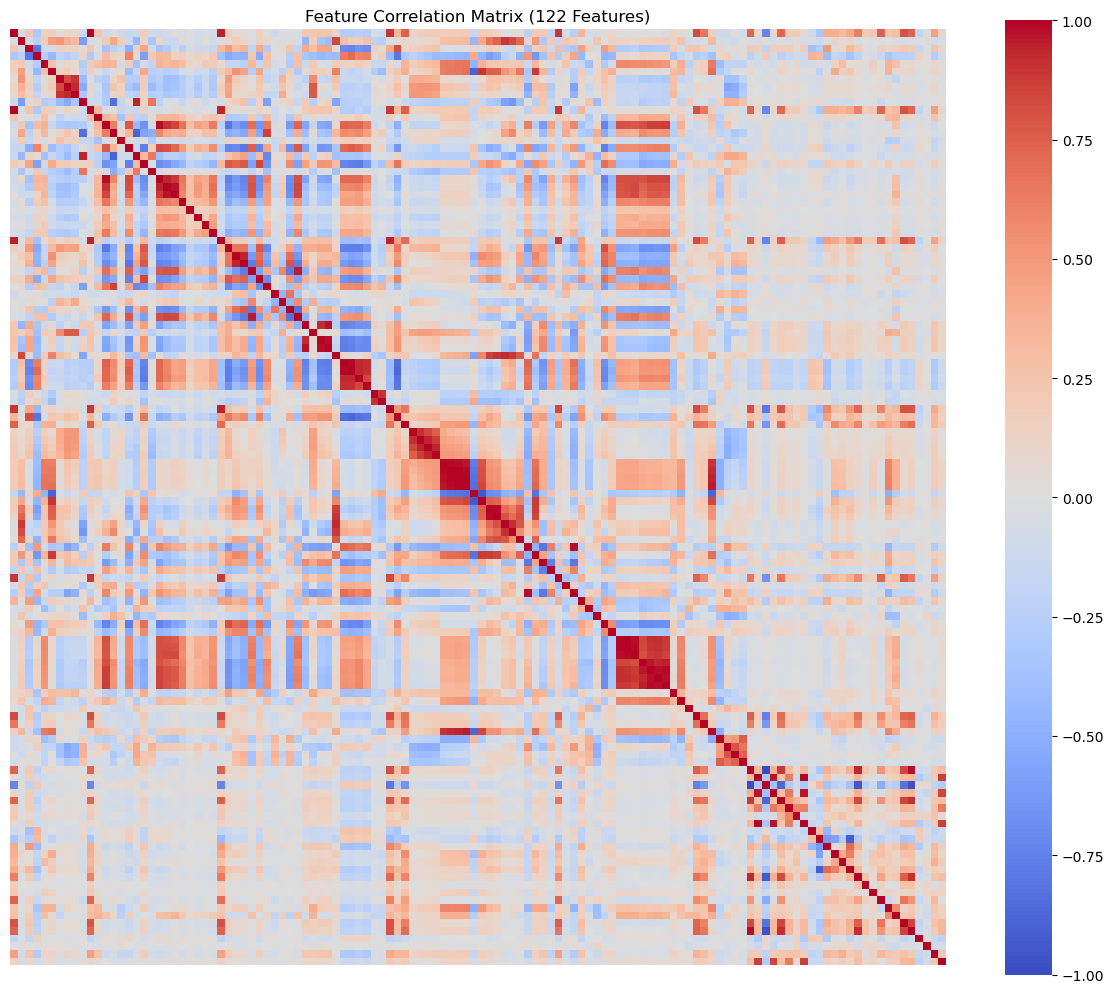

In [49]:
plt.figure(figsize=(12, 10))

corr_matrix = X_train.corr()

sns.heatmap(
    corr_matrix, 
    cmap="coolwarm",    
    vmin=-1, vmax=1,    
    xticklabels=False,  
    yticklabels=False,  
    square=True
)

plt.title("Feature Correlation Matrix (122 Features)")
plt.tight_layout()
plt.show()

### (d) Calculate the Coefficient of Variation CV

In [51]:
means = X_train.mean()
stds = X_train.std()

cv_scores = stds / (means)

cv_scores_sorted = cv_scores.sort_values(ascending=False)

print("Top 20 features with the highest Coefficient of Variation (CV):")
print(cv_scores_sorted.head(20))

Top 20 features with the highest Coefficient of Variation (CV):
113    5.527059
95     4.292923
94     3.470952
54     3.058964
56     2.926635
125    2.552946
32     2.342443
101    2.248042
5      2.241105
15     2.038461
76     1.968467
122    1.645508
118    1.645408
10     1.612091
66     1.456618
105    1.451887
7      1.428885
120    1.397110
9      1.359100
112    1.353882
dtype: float64


### (e) Scatter plots and box plots for highest CV features

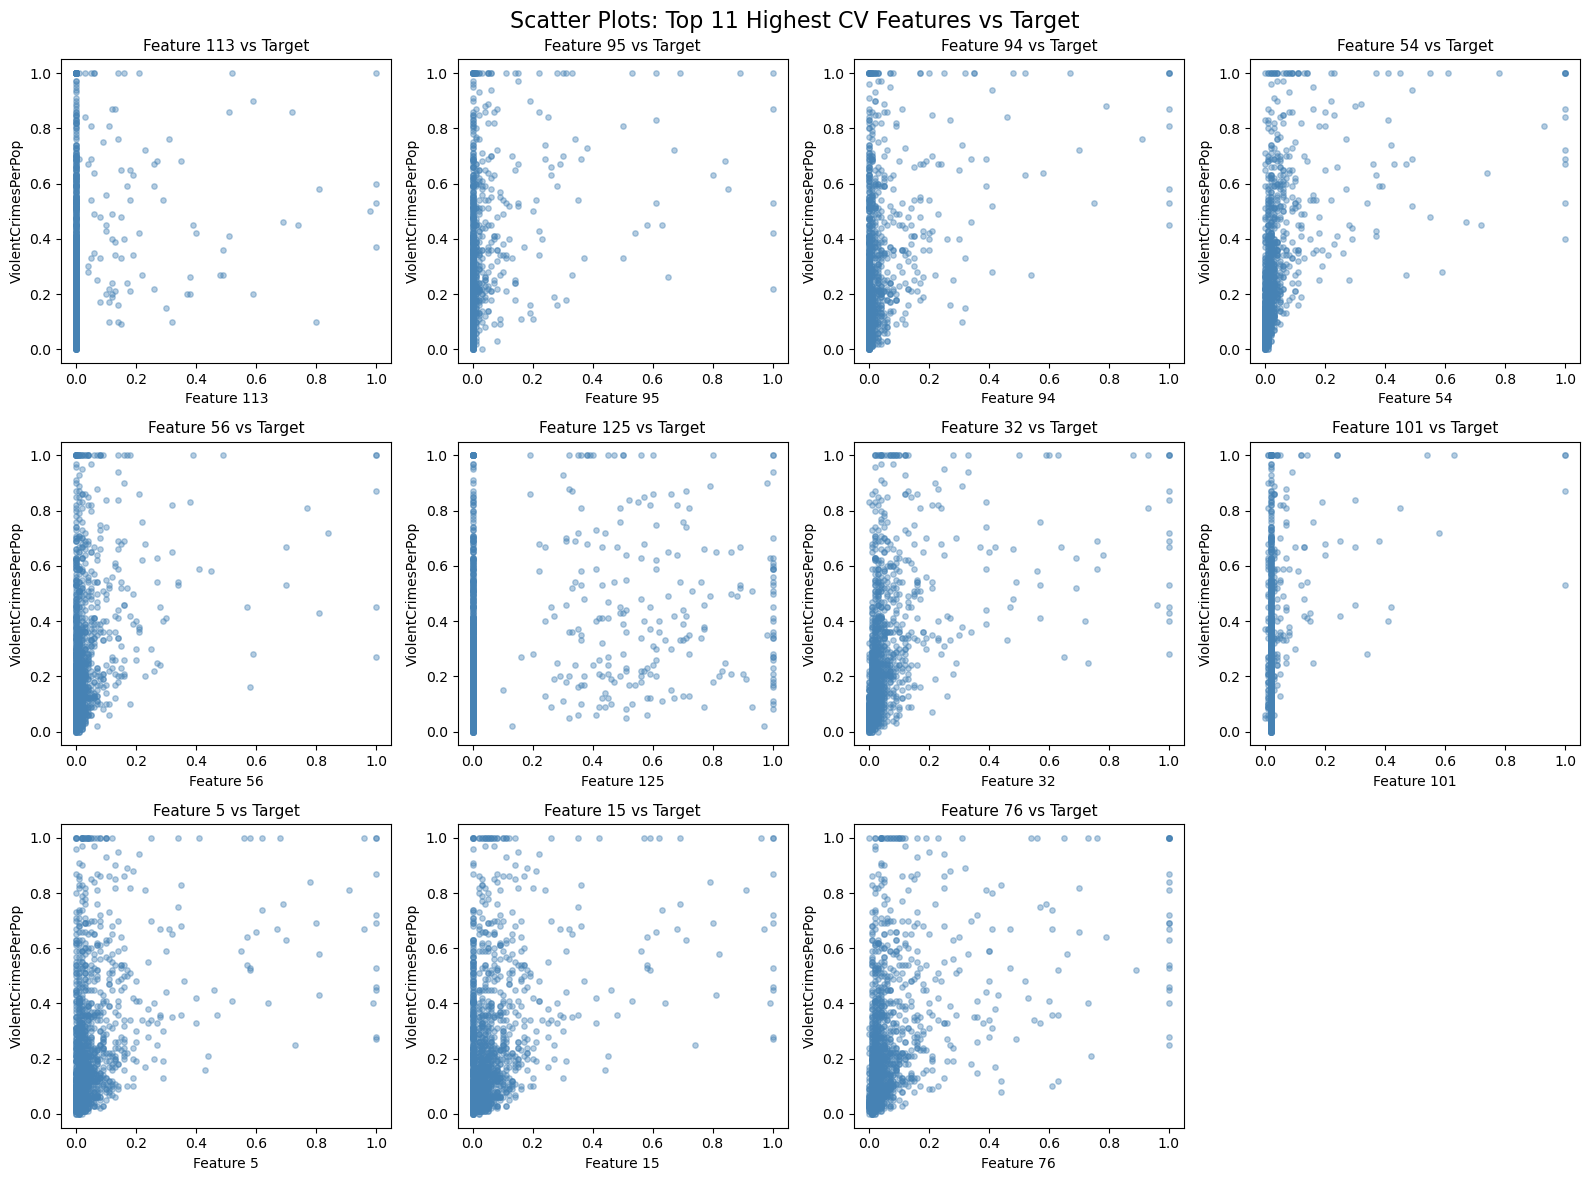

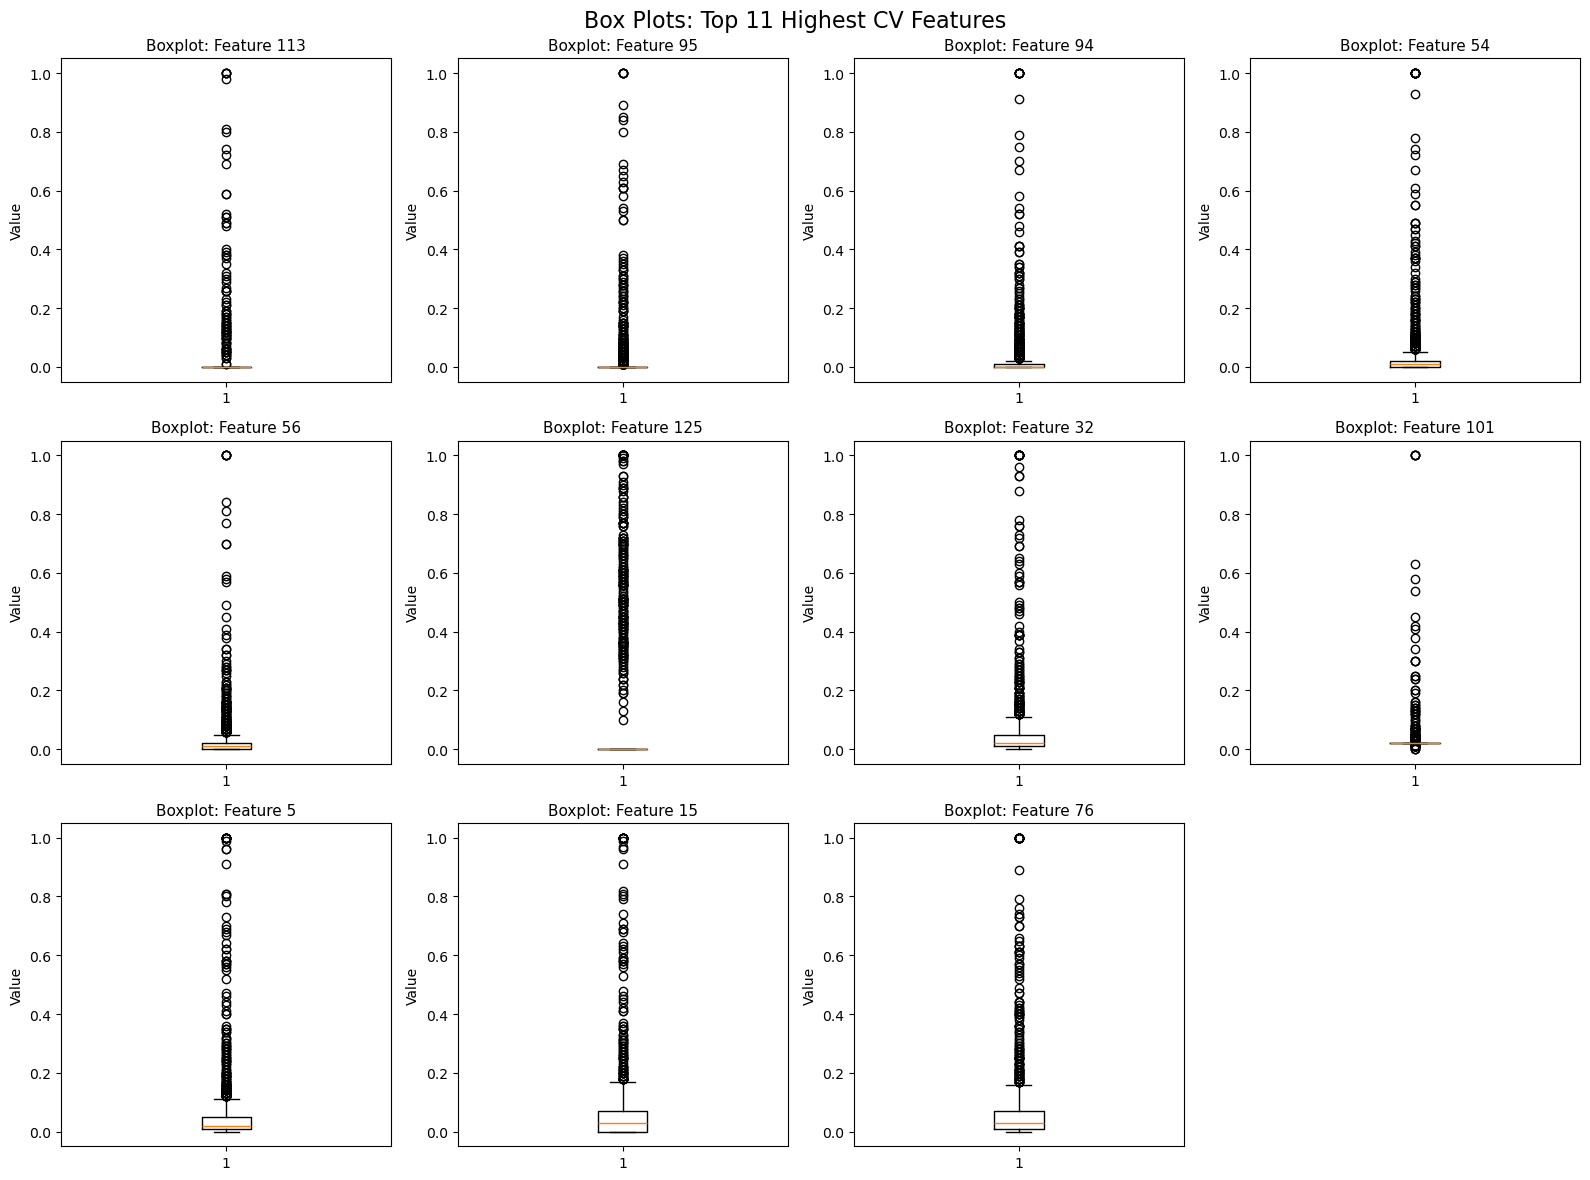

In [53]:
top_11_features = cv_scores.sort_values(ascending=False).head(11).index.tolist()

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.flatten()

for i, feat in enumerate(top_11_features):
    axes[i].scatter(X_train[feat], y_train, alpha=0.4, s=15, color='steelblue')
    axes[i].set_xlabel(f"Feature {feat}", fontsize=10)
    axes[i].set_ylabel("ViolentCrimesPerPop", fontsize=10)
    axes[i].set_title(f"Feature {feat} vs Target", fontsize=11)

axes[-1].axis('off') 
plt.suptitle("Scatter Plots: Top 11 Highest CV Features vs Target", fontsize=16)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.flatten()

for i, feat in enumerate(top_11_features):
    axes[i].boxplot(X_train[feat].dropna())
    axes[i].set_title(f"Boxplot: Feature {feat}", fontsize=11)
    axes[i].set_ylabel("Value", fontsize=10)

axes[-1].axis('off')
plt.suptitle("Box Plots: Top 11 Highest CV Features", fontsize=16)
plt.tight_layout()
plt.show()

No.

Univariate Limitation: Scatter plots only show the marginal (univariate) relationship between a single feature and the target. If a scatter plot looks like a mess (no clear linear trend), it doesn't mean the feature is unimportant in a multivariate regression; conversely, a visible trend doesn't guarantee significance.

Multicollinearity: The Communities and Crime dataset has severe multicollinearity (as seen in your 2(c) heatmap). A feature showing a strong correlation in a scatter plot might just be "free-riding" on another highly correlated, truly predictive feature.

Interaction Effects: Scatter plots cannot reveal interactions between features. Some features may only be predictive when combined with others.

Outliers: As seen in the box plots, features with high CV often contain many extreme outliers. These outliers can severely distort the visual trend in scatter plots.

### (f) Fit a linear model

In [58]:
ols_model = LinearRegression()

ols_model.fit(X_train, y_train)

y_pred_ols = ols_model.predict(X_test)

mse_ols = mean_squared_error(y_test, y_pred_ols)
r2_ols = r2_score(y_test, y_pred_ols)

print(f"OLS Test Mean Squared Error (MSE): {mse_ols:.6f}")
print(f"OLS Test R-squared (R2): {r2_ols:.6f}")

OLS Test Mean Squared Error (MSE): 0.017966
OLS Test R-squared (R2): 0.622204


### (g) Fit a ridge regression model

In [64]:
alphas = np.logspace(-3, 5, 100)

ridge_model = RidgeCV(alphas=alphas, cv=5)

ridge_model.fit(X_train, y_train)

y_pred_ridge = ridge_model.predict(X_test)

mse_ridge = mean_squared_error(y_test, y_pred_ridge)
r2_ridge = r2_score(y_test, y_pred_ridge)

print(f"Best lambda (alpha) chosen by CV: {ridge_model.alpha_:.6f}")
print(f"Ridge Test Mean Squared Error (MSE): {mse_ridge:.6f}")
print(f"Ridge Test R-squared (R2): {r2_ridge:.6f}")

Best lambda (alpha) chosen by CV: 2.477076
Ridge Test Mean Squared Error (MSE): 0.017508
Ridge Test R-squared (R2): 0.631847


### (h) Fit a LASSO model

In [70]:
lasso_raw = LassoCV(cv=5, random_state=42, max_iter=10000)
lasso_raw.fit(X_train, y_train)

y_pred_lasso_raw = lasso_raw.predict(X_test)
mse_lasso_raw = mean_squared_error(y_test, y_pred_lasso_raw)
r2_lasso_raw = r2_score(y_test, y_pred_lasso_raw)

selected_features_raw = X_train.columns[lasso_raw.coef_ != 0].tolist()

print("--- LASSO (Raw Features) ---")
print(f"Best alpha: {lasso_raw.alpha_:.6f}")
print(f"Test MSE: {mse_lasso_raw:.6f}")
print(f"Test R2: {r2_lasso_raw:.6f}")
print(f"Number of selected features: {len(selected_features_raw)} (out of {X_train.shape[1]})")
print(f"Selected features: {selected_features_raw}\n")


scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

lasso_std = LassoCV(cv=5, random_state=42, max_iter=10000)
lasso_std.fit(X_train_scaled, y_train)

y_pred_lasso_std = lasso_std.predict(X_test_scaled)
mse_lasso_std = mean_squared_error(y_test, y_pred_lasso_std)
r2_lasso_std = r2_score(y_test, y_pred_lasso_std)

selected_features_std = X_train.columns[lasso_std.coef_ != 0].tolist()

print("--- LASSO (Standardized Features) ---")
print(f"Best alpha: {lasso_std.alpha_:.6f}")
print(f"Test MSE: {mse_lasso_std:.6f}")
print(f"Test R2: {r2_lasso_std:.6f}")
print(f"Number of selected features: {len(selected_features_std)} (out of {X_train.shape[1]})")
print(f"Selected features: {selected_features_std}\n")

--- LASSO (Raw Features) ---
Best alpha: 0.000125
Test MSE: 0.017618
Test R2: 0.629531
Number of selected features: 74 (out of 122)
Selected features: [7, 9, 11, 12, 16, 18, 19, 20, 21, 22, 23, 26, 27, 28, 29, 30, 31, 33, 34, 38, 39, 41, 43, 44, 45, 49, 50, 51, 53, 54, 55, 56, 57, 60, 64, 66, 68, 69, 72, 73, 74, 75, 76, 77, 79, 80, 81, 82, 83, 84, 87, 90, 91, 92, 93, 94, 95, 96, 97, 99, 104, 107, 109, 111, 112, 113, 116, 117, 118, 119, 120, 121, 123, 124]

--- LASSO (Standardized Features) ---
Best alpha: 0.000763
Test MSE: 0.017682
Test R2: 0.628180
Number of selected features: 72 (out of 122)
Selected features: [7, 9, 11, 12, 16, 18, 19, 20, 21, 22, 23, 26, 27, 28, 29, 30, 31, 33, 34, 38, 39, 43, 44, 45, 49, 50, 51, 53, 54, 55, 56, 58, 60, 64, 66, 68, 69, 72, 73, 74, 76, 77, 79, 80, 81, 82, 83, 87, 90, 91, 92, 93, 94, 95, 96, 99, 104, 105, 107, 109, 111, 112, 113, 115, 116, 117, 118, 119, 120, 121, 123, 124]



### (i) Fit a PCR model

In [82]:
pcr_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA()),
    ('lr', LinearRegression())
])

param_grid = {'pca__n_components': range(1, X_train.shape[1] + 1)}

pcr_grid = GridSearchCV(pcr_pipeline, param_grid, cv=5, scoring='neg_mean_squared_error')
pcr_grid.fit(X_train, y_train)

best_m = pcr_grid.best_params_['pca__n_components']
y_pred_pcr = pcr_grid.predict(X_test)
mse_pcr = mean_squared_error(y_test, y_pred_pcr)
r2_pcr = r2_score(y_test, y_pred_pcr)

print(f"--- PCR Model ---")
print(f"Best number of components (M): {best_m}")
print(f"PCR Test Mean Squared Error (MSE): {mse_pcr:.6f}")
print(f"PCR Test R-squared (R2): {r2_pcr:.6f}")

--- PCR Model ---
Best number of components (M): 95
PCR Test Mean Squared Error (MSE): 0.018297
PCR Test R-squared (R2): 0.615250


### (j) Fit a boosting tree

In [86]:
pip install xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 10.6 MB/s eta 0:00:00a 0:00:01
Note: you may need to restart the kernel to use updated packages.


In [88]:
import xgboost as xgb


xgb_model = xgb.XGBRegressor(objective='reg:squarederror', random_state=42, n_jobs=-1)

param_grid_xgb = {'alpha': [0, 0.01, 0.1, 1, 10]}

xgb_grid = GridSearchCV(xgb_model, param_grid_xgb, cv=5, scoring='neg_mean_squared_error')
xgb_grid.fit(X_train, y_train)

best_alpha_xgb = xgb_grid.best_params_['alpha']
best_xgb = xgb_grid.best_estimator_
y_pred_xgb = best_xgb.predict(X_test)

mse_xgb = mean_squared_error(y_test, y_pred_xgb)
r2_xgb = r2_score(y_test, y_pred_xgb)

print(f"--- XGBoost Model ---")
print(f"Best alpha (L1 penalty): {best_alpha_xgb}")
print(f"XGBoost Test Mean Squared Error (MSE): {mse_xgb:.6f}")
print(f"XGBoost Test R-squared (R2): {r2_xgb:.6f}")

--- XGBoost Model ---
Best alpha (L1 penalty): 1
XGBoost Test Mean Squared Error (MSE): 0.017927
XGBoost Test R-squared (R2): 0.623026
